<h1>Table of Contents<span class="tocSkip"></span></h1>
<div class="toc"><ul class="toc-item"></ul></div>

Numerical check for matrix Sokhotski-Plemelj in Appendix B.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(743)
np.set_printoptions(precision=3)

In [2]:
N = 7

X = np.random.rand(N, N)
Y = np.random.rand(N, N)

# make diagonal elements small
np.fill_diagonal(X, 0.01 * np.diag(X))
np.fill_diagonal(Y, 0.01 * np.diag(Y))

print("X: \n", X)
print("Y: \n", Y)

X: 
 [[0.008 0.944 0.575 0.09  0.084 0.433 0.3  ]
 [0.115 0.003 0.906 0.698 0.527 0.132 0.446]
 [0.625 0.444 0.008 0.348 0.889 0.911 0.446]
 [0.051 0.356 0.967 0.002 0.888 0.36  0.81 ]
 [0.632 0.14  0.327 0.829 0.002 0.776 0.436]
 [0.07  0.029 0.034 0.211 0.033 0.003 0.087]
 [0.055 0.348 0.199 0.63  0.485 0.753 0.007]]
Y: 
 [[6.593e-03 7.729e-01 3.630e-01 1.430e-01 9.531e-01 5.699e-01 9.895e-01]
 [9.852e-01 7.913e-03 8.176e-01 9.227e-01 1.538e-01 3.539e-01 4.066e-02]
 [9.397e-01 9.904e-01 5.716e-03 7.014e-01 2.104e-01 3.380e-01 6.933e-01]
 [4.619e-02 6.513e-02 6.832e-01 4.850e-03 1.046e-01 3.695e-01 7.370e-01]
 [6.003e-01 7.539e-01 7.451e-01 2.820e-01 6.984e-03 7.376e-01 7.687e-01]
 [3.498e-01 6.990e-02 6.857e-01 4.932e-03 4.703e-01 2.450e-03 8.528e-01]
 [8.565e-01 5.219e-01 5.447e-01 9.890e-02 8.806e-01 6.027e-01 8.886e-04]]


\begin{align}
    \Sigma^R &= \Xi - i \Gamma \\
    \Sigma^A &= \Xi + i \Gamma
\end{align}

In [3]:
eta = 0.01

# Gamma is diagonal by assumption
Gamma = np.diag(np.random.rand(N))
Gamma = np.abs(Gamma)
Gamma = eta * Gamma

# Xi = np.zeros((N, N))
Xi = np.random.rand(N, N)
Xi = eta * Xi

SigmaR = Xi - 1j * Gamma
SigmaA = Xi + 1j * Gamma

\begin{align}
    [(X-\Sigma^R)^{-1} (\Sigma^R - \Sigma^A) (Y - \Sigma^A)^{-1}]_{ac} 
    \approx -2 \pi i \sum_b (X-\Xi)^{-1}_{ab} \delta((X-\Xi)_{bb}) (Y-\Xi)^{-1}_{bc}
\end{align}

Divergence occurs when the diagonal elements of $X$ and $Y$ are small in the eigenbasis of $\Gamma$.

In [4]:
left = np.linalg.inv(X - SigmaR)
right = np.linalg.inv(Y - SigmaA)
center = SigmaR - SigmaA

result = left @ center @ right
result = (X - Xi) @ result @ (Y - Xi) /(-2j * np.pi) # center part of RHS

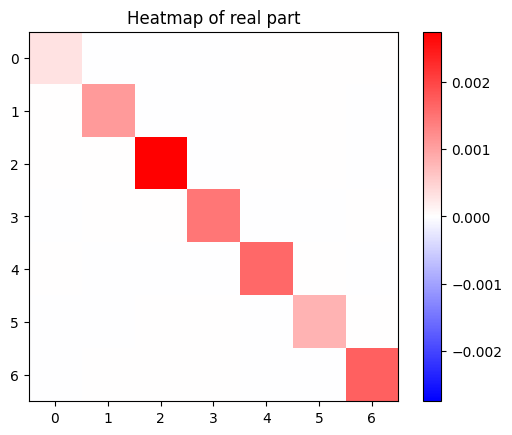

In [5]:
result_re = np.real(result)

# expecting a strongly diagonal plot
vmax = np.max(np.abs(result_re))
plt.imshow(result_re, cmap='bwr', vmin=-vmax, vmax=vmax)
plt.colorbar()
plt.title("Heatmap of real part")
plt.show()

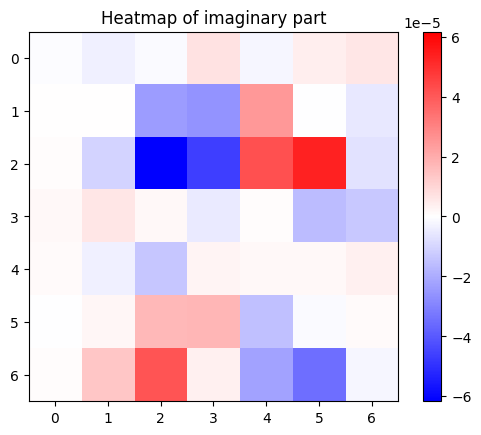

In [6]:
result_im = np.imag(result)

vmax = np.max(np.abs(result_im))
plt.imshow(result_im, cmap='bwr', vmin=-vmax, vmax=vmax)
plt.colorbar()
plt.title("Heatmap of imaginary part")
plt.show()